# User Study Analysis




# Setup

In [1]:
import csv
import re
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

DATA_DIR = Path(".")
RESPONSES_CSV = DATA_DIR / "user_study_responses.csv"
MAPPING_XLSX = DATA_DIR / "user_study_mapping.xlsx"

# Fallback: if the CSV was not renamed yet, use the newest CSV in this folder.
if not RESPONSES_CSV.exists():
    csv_files = sorted(DATA_DIR.glob("*.csv"), key=lambda p: p.stat().st_mtime, reverse=True)
    if not csv_files:
        raise FileNotFoundError("No user study CSV found. Put it in this folder or rename it to user_study_responses.csv")
    RESPONSES_CSV = csv_files[0]

print("responses:", RESPONSES_CSV)
print("mapping:", MAPPING_XLSX)


responses: user_study_responses.csv
mapping: user_study_mapping.xlsx


# Helpers

In [2]:
def _col_letters(cell_ref: str) -> str:
    return "".join(ch for ch in cell_ref if ch.isalpha())


def read_xlsx_cells(path: Path, sheet_name: str = "xl/worksheets/sheet1.xml") -> list[dict]:
    """Read an XLSX worksheet without requiring openpyxl.

    Returns rows as dictionaries keyed by Excel column letters: A, B, C, ...
    This is useful here because the mapping file is tiny and the key columns are E and G.
    """
    with zipfile.ZipFile(path) as z:
        shared = []
        try:
            root = ET.fromstring(z.read("xl/sharedStrings.xml"))
            ns = {"x": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
            for si in root.findall(".//x:si", ns):
                shared.append("".join(t.text or "" for t in si.findall(".//x:t", ns)))
        except KeyError:
            pass

        root = ET.fromstring(z.read(sheet_name))
        ns = {"x": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
        rows = []
        for row in root.findall(".//x:sheetData/x:row", ns):
            out = {}
            for c in row.findall("x:c", ns):
                col = _col_letters(c.attrib.get("r", ""))
                v = c.find("x:v", ns)
                val = "" if v is None else (v.text or "")
                if c.attrib.get("t") == "s" and val != "":
                    val = shared[int(val)]
                out[col] = val
            rows.append(out)
        return rows


def parse_completion_time(value):
    """Convert Jotform completion time like 'Time taken to fill form: 00:14:33' to minutes."""
    if pd.isna(value):
        return np.nan
    m = re.search(r"(\d{1,2}:\d{2}:\d{2})", str(value))
    if not m:
        return np.nan
    return pd.to_timedelta(m.group(1)).total_seconds() / 60


def clean_multiselect(value):
    if pd.isna(value):
        return []
    return [x.strip() for x in str(value).split("\n") if x.strip()]


# Load Data

In [3]:
df_raw = pd.read_csv(RESPONSES_CSV)
print(df_raw.shape)
df_raw.head()


(23, 48)


,Submission Date,C10. Intelligibility,C10. Scriptedness,C10. Confidence,C10. Empathy,Gender,Age,What do you do for a living?,How would you rate your English proficiency level?,C1. Intelligibility,What is/are your native language/s?,C1. Confidence,What type of audio device did you use to listen to the clips?,C1. Scriptedness,Completion Time,C1. Empathy,C2. Intelligibility,C2. Scriptedness,C2. Confidence,C2. Empathy,C3. Intelligibility,C3. Scriptedness,C3. Confidence,C3. Empathy,C4. Intelligibility,C4. Scriptedness,C4. Confidence,C4. Empathy,C5. Intelligibility,C5. Confidence,C5. Scriptedness,C5. Empathy,C6. Intelligibility,C6. Scriptedness,C6. Confidence,C6. Empathy,C7. Intelligibility,C7. Scriptedness,C7. Confidence,C7. Empathy,C8. Intelligibility,C8. Scriptedness,C8. Confidence,C8. Empathy,C9. Intelligibility,C9. Scriptedness,C9. Confidence,C9. Empathy
0,"Aug 30, 2026",3,4,4,2,Male,24,Technological Role,Fluent (I can speak freely in English and unde...,5,Hebrew,4,Headphones / Earbuds,4,Time taken to fill form: 00:12:49,5,5,3,4,5,4,2,2,4,4,3,2,3,4,2,2,2,5,2,4,4,4,1,2,4,4,2,4,4,4,4,2,3
1,"Aug 30, 2026",5,5,5,2,Female,26,Student,Fluent (I can speak freely in English and unde...,5,Hebrew\nRussian,2,Monitor speakers / External desktop speakers /...,5,Time taken to fill form: 00:01:20,3,5,1,5,3,5,3,5,3,5,4,5,3,5,4,1,3,5,3,5,4,5,5,5,3,5,3,3,2,5,2,3,4
2,"Aug 30, 2026",5,4,5,5,Male,21,Student\nAcademic / Researcher / Educator,Fluent (I can speak freely in English and unde...,5,Hebrew,3,Monitor speakers / External desktop speakers /...,3,Time taken to fill form: 00:05:43,2,5,2,3,5,5,3,4,4,5,3,5,2,5,2,3,1,5,4,4,4,5,3,4,4,5,3,2,4,5,3,4,4
3,"Aug 30, 2026",4,5,5,2,Male,23,Student,Intermediate (I can handle most everyday conve...,4,Russian,3,Monitor speakers / External desktop speakers /...,4,Time taken to fill form: 00:08:34,3,3,3,4,3,4,4,4,2,4,2,2,4,4,3,3,2,4,4,2,2,4,4,2,2,3,2,1,3,4,4,4,4
4,"Aug 29, 2026",5,3,2,4,Male,22,Student,"Native or Bilingual (If you mark this, you sho...",5,Hebrew\nEnglish,3,Headphones / Earbuds,5,Time taken to fill form: 00:09:49,1,5,2,4,4,5,5,5,1,5,2,5,5,5,4,1,4,5,3,3,5,5,2,4,4,5,1,4,3,5,2,4,5


In [4]:
mapping_rows = read_xlsx_cells(MAPPING_XLSX)

mapping_records = []
for row in mapping_rows[1:]:
    if not row.get("E") or not row.get("G"):
        continue
    q_num = int(float(row["E"]))
    mapping_records.append({
        "question": f"C{q_num}",
        "question_num": q_num,
        "convo_num": row.get("A", ""),
        "fluent_flag": row.get("B", ""),
        "gemma_flag": row.get("C", ""),
        "random_order": row.get("F", ""),
        "condition_short": row.get("G", "").strip(),
    })

mapping = pd.DataFrame(mapping_records).sort_values("question_num")
mapping["condition"] = mapping["condition_short"].map({"F": "Fluent", "D": "Disfluent"}).fillna(mapping["condition_short"])
mapping


,question,question_num,convo_num,fluent_flag,gemma_flag,random_order,condition_short,condition
0,C1,1,11,1,0,18,F,Fluent
1,C2,2,12,0,1,19,D,Disfluent
2,C3,3,13,0,0,16,F,Fluent
3,C4,4,14,1,1,15,F,Fluent
4,C5,5,15,0,0,11,D,Disfluent
5,C6,6,16,0,0,17,F,Fluent
6,C7,7,17,1,0,14,D,Disfluent
7,C8,8,18,1,1,20,D,Disfluent
8,C9,9,19,1,1,12,D,Disfluent
9,C10,10,20,1,0,13,F,Fluent


# Preprocessing

In [5]:
df = df_raw.copy()

rename_cols = {
    "What do you do for a living?": "Occupation",
    "How would you rate your English proficiency level?": "English Proficiency",
    "What is/are your native language/s": "Native Languages",
    "What is/are your native language/s?": "Native Languages",
    "What type of audio device did you use to listen to the clips?": "Audio Device",
}
df = df.rename(columns={k: v for k, v in rename_cols.items() if k in df.columns})

if "Completion Time" in df.columns:
    df["Completion Time (min)"] = df["Completion Time"].apply(parse_completion_time)

for col in ["Occupation", "Native Languages", "Audio Device"]:
    if col in df.columns:
        df[col] = df[col].apply(clean_multiselect)

participant_id = np.arange(1, len(df) + 1)
df.insert(0, "Participant_ID", participant_id)

print("Participants:", len(df))
print("Columns:", len(df.columns))
df.head()


Participants: 23
Columns: 50


,Participant_ID,Submission Date,C10. Intelligibility,C10. Scriptedness,C10. Confidence,C10. Empathy,Gender,Age,Occupation,English Proficiency,C1. Intelligibility,Native Languages,C1. Confidence,Audio Device,C1. Scriptedness,Completion Time,C1. Empathy,C2. Intelligibility,C2. Scriptedness,C2. Confidence,C2. Empathy,C3. Intelligibility,C3. Scriptedness,C3. Confidence,C3. Empathy,C4. Intelligibility,C4. Scriptedness,C4. Confidence,C4. Empathy,C5. Intelligibility,C5. Confidence,C5. Scriptedness,C5. Empathy,C6. Intelligibility,C6. Scriptedness,C6. Confidence,C6. Empathy,C7. Intelligibility,C7. Scriptedness,C7. Confidence,C7. Empathy,C8. Intelligibility,C8. Scriptedness,C8. Confidence,C8. Empathy,C9. Intelligibility,C9. Scriptedness,C9. Confidence,C9. Empathy,Completion Time (min)
0,1,"Aug 30, 2026",3,4,4,2,Male,24,[Technological Role],Fluent (I can speak freely in English and unde...,5,[Hebrew],4,[Headphones / Earbuds],4,Time taken to fill form: 00:12:49,5,5,3,4,5,4,2,2,4,4,3,2,3,4,2,2,2,5,2,4,4,4,1,2,4,4,2,4,4,4,4,2,3,12.82
1,2,"Aug 30, 2026",5,5,5,2,Female,26,[Student],Fluent (I can speak freely in English and unde...,5,"[Hebrew, Russian]",2,[Monitor speakers / External desktop speakers ...,5,Time taken to fill form: 00:01:20,3,5,1,5,3,5,3,5,3,5,4,5,3,5,4,1,3,5,3,5,4,5,5,5,3,5,3,3,2,5,2,3,4,1.33
2,3,"Aug 30, 2026",5,4,5,5,Male,21,"[Student, Academic / Researcher / Educator]",Fluent (I can speak freely in English and unde...,5,[Hebrew],3,[Monitor speakers / External desktop speakers ...,3,Time taken to fill form: 00:05:43,2,5,2,3,5,5,3,4,4,5,3,5,2,5,2,3,1,5,4,4,4,5,3,4,4,5,3,2,4,5,3,4,4,5.72
3,4,"Aug 30, 2026",4,5,5,2,Male,23,[Student],Intermediate (I can handle most everyday conve...,4,[Russian],3,[Monitor speakers / External desktop speakers ...,4,Time taken to fill form: 00:08:34,3,3,3,4,3,4,4,4,2,4,2,2,4,4,3,3,2,4,4,2,2,4,4,2,2,3,2,1,3,4,4,4,4,8.57
4,5,"Aug 29, 2026",5,3,2,4,Male,22,[Student],"Native or Bilingual (If you mark this, you sho...",5,"[Hebrew, English]",3,[Headphones / Earbuds],5,Time taken to fill form: 00:09:49,1,5,2,4,4,5,5,5,1,5,2,5,5,5,4,1,4,5,3,3,5,5,2,4,4,5,1,4,3,5,2,4,5,9.82


# Convert Ratings To Long Format

In [6]:
METRICS = ["Intelligibility", "Scriptedness", "Confidence", "Empathy"]

long_rows = []
for _, participant in df.iterrows():
    for _, mrow in mapping.iterrows():
        question = mrow["question"]
        for metric in METRICS:
            col = f"{question}. {metric}"
            if col not in df.columns:
                continue
            score = participant.get(col)
            if pd.isna(score) or score == "":
                continue
            long_rows.append({
                "Participant_ID": participant["Participant_ID"],
                "question": question,
                "question_num": mrow["question_num"],
                "metric": metric,
                "score": float(score),
                "condition": mrow["condition"],
                "condition_short": mrow["condition_short"],
                "convo_num": mrow["convo_num"],
                "fluent_flag": mrow["fluent_flag"],
                "gemma_flag": mrow["gemma_flag"],
                "random_order": mrow["random_order"],
            })

long_df = pd.DataFrame(long_rows)
expected = len(df) * len(mapping) * len(METRICS)
print(f"Rating rows: {len(long_df)} / expected {expected}")
long_df.head()


Rating rows: 920 / expected 920


,Participant_ID,question,question_num,metric,score,condition,condition_short,convo_num,fluent_flag,gemma_flag,random_order
0,1,C1,1,Intelligibility,5.00,Fluent,F,11,1,0,18
1,1,C1,1,Scriptedness,4.00,Fluent,F,11,1,0,18
2,1,C1,1,Confidence,4.00,Fluent,F,11,1,0,18
3,1,C1,1,Empathy,5.00,Fluent,F,11,1,0,18
4,1,C2,2,Intelligibility,5.00,Disfluent,D,12,0,1,19


# Basic Data Quality Checks

In [7]:
completion = (
    long_df.groupby("Participant_ID")["score"]
    .count()
    .rename("n_ratings")
    .reset_index()
)
completion["complete"] = completion["n_ratings"] == len(mapping) * len(METRICS)
print("Complete participants:", completion["complete"].sum(), "/", len(completion))
completion.head()


Complete participants: 23 / 23


,Participant_ID,n_ratings,complete
0,1,40,True
1,2,40,True
2,3,40,True
3,4,40,True
4,5,40,True


In [8]:
summary = (
    long_df.groupby(["condition", "metric"])["score"]
    .agg(n="count", mean="mean", std="std", median="median")
    .reset_index()
)
summary


,condition,metric,n,mean,std,median
0,Disfluent,Confidence,115,3.04,1.00,3.00
1,Disfluent,Empathy,115,3.23,0.97,3.00
2,Disfluent,Intelligibility,115,3.83,0.98,4.00
3,Disfluent,Scriptedness,115,2.85,1.20,3.00
4,Fluent,Confidence,115,3.65,0.91,4.00
5,Fluent,Empathy,115,2.98,1.18,3.00
6,Fluent,Intelligibility,115,4.18,0.94,4.00
7,Fluent,Scriptedness,115,3.55,1.10,4.00


# Main Plot: Ratings By Condition

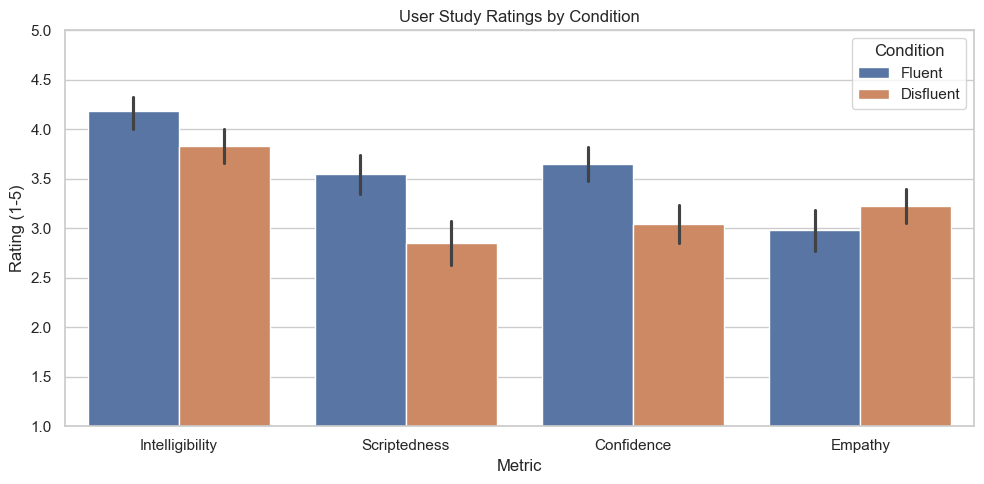

In [9]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=long_df,
    x="metric",
    y="score",
    hue="condition",
    errorbar=("ci", 95),
    palette={"Fluent": "#4C72B0", "Disfluent": "#DD8452"},
)
plt.title("User Study Ratings by Condition")
plt.xlabel("Metric")
plt.ylabel("Rating (1-5)")
plt.ylim(1, 5)
plt.legend(title="Condition")
plt.tight_layout()
plt.show()


# Rating Distributions

C:\Users\nooro\AppData\Local\Temp\ipykernel_28276\3748970941.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(


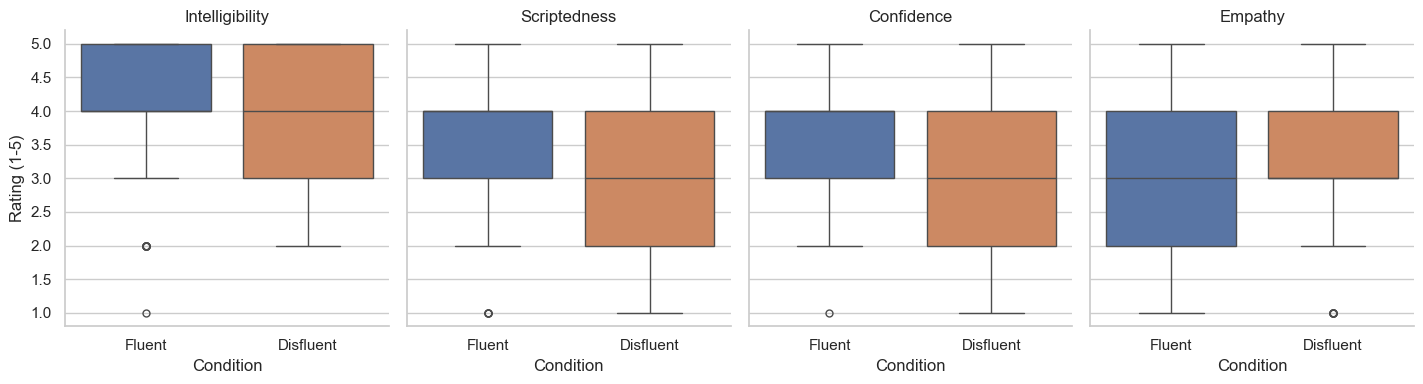

In [10]:
g = sns.catplot(
    data=long_df,
    x="condition",
    y="score",
    col="metric",
    kind="box",
    col_wrap=4,
    height=4,
    aspect=0.9,
    palette={"Fluent": "#4C72B0", "Disfluent": "#DD8452"},
)
g.set_axis_labels("Condition", "Rating (1-5)")
g.set_titles("{col_name}")
plt.tight_layout()
plt.show()


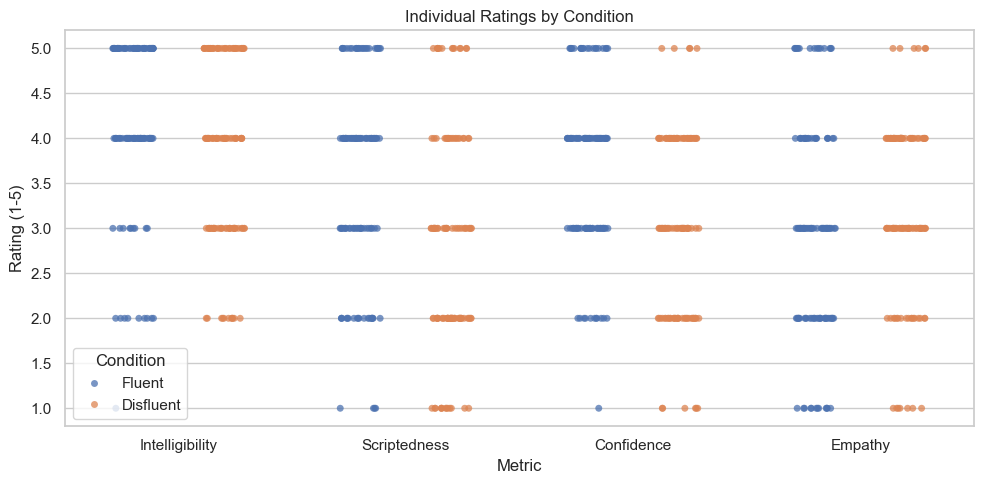

In [11]:
plt.figure(figsize=(10, 5))
sns.stripplot(
    data=long_df,
    x="metric",
    y="score",
    hue="condition",
    dodge=True,
    jitter=0.18,
    alpha=0.75,
    palette={"Fluent": "#4C72B0", "Disfluent": "#DD8452"},
)
plt.title("Individual Ratings by Condition")
plt.xlabel("Metric")
plt.ylabel("Rating (1-5)")
plt.ylim(0.8, 5.2)
plt.legend(title="Condition")
plt.tight_layout()
plt.show()


# Participant Metadata

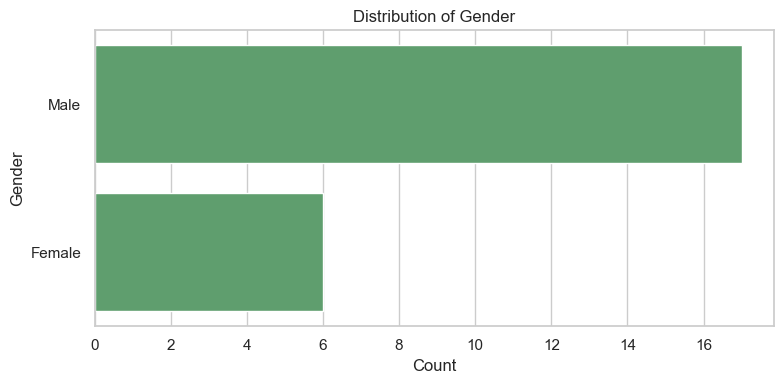

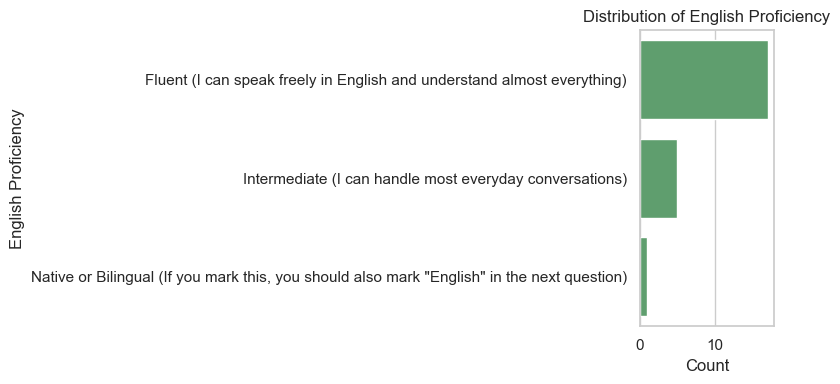

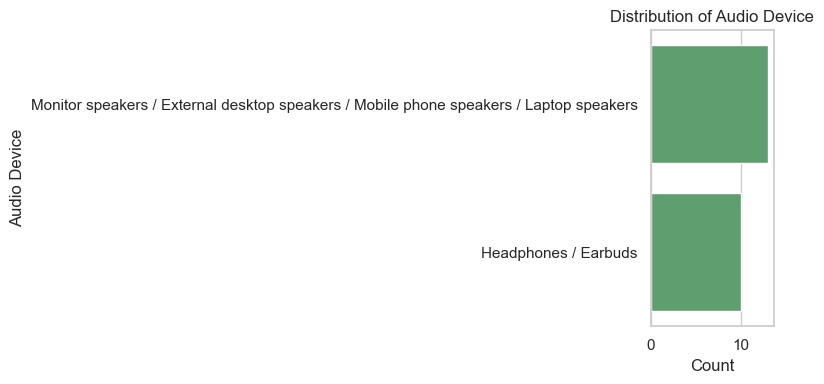

In [12]:
categorical_cols = [c for c in ["Gender", "English Proficiency", "Audio Device"] if c in df.columns]

for col in categorical_cols:
    exploded = df.explode(col) if df[col].apply(lambda x: isinstance(x, list)).any() else df
    plt.figure(figsize=(8, 4))
    order = exploded[col].astype(str).value_counts().index
    sns.countplot(data=exploded, y=col, order=order, color="#55A868")
    plt.title(f"Distribution of {col}")
    plt.xlabel("Count")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


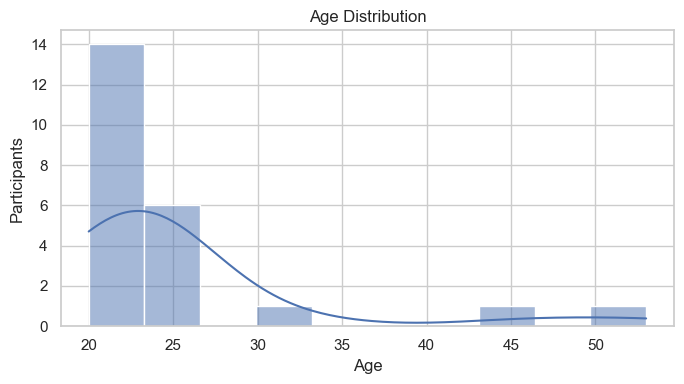

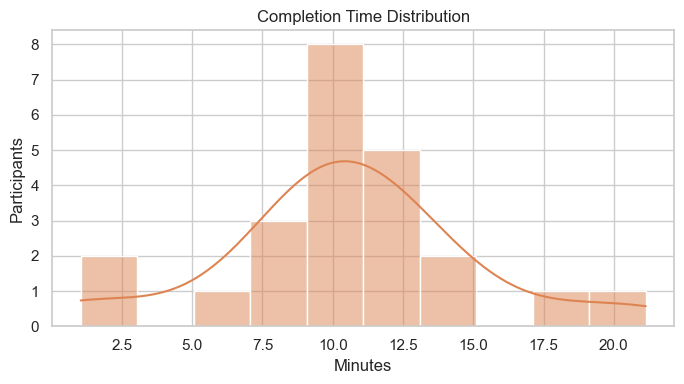

In [13]:
if "Age" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(df["Age"], bins=10, kde=True, color="#4C72B0")
    plt.title("Age Distribution")
    plt.xlabel("Age")
    plt.ylabel("Participants")
    plt.tight_layout()
    plt.show()

if "Completion Time (min)" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(df["Completion Time (min)"], bins=10, kde=True, color="#DD8452")
    plt.title("Completion Time Distribution")
    plt.xlabel("Minutes")
    plt.ylabel("Participants")
    plt.tight_layout()
    plt.show()


# Statistical Tests

Because each participant rates both fluent and disfluent samples, the paired test below compares each participant's average rating under each condition. With small sample sizes, treat p-values as exploratory.


In [14]:
from scipy.stats import ttest_rel, wilcoxon

participant_condition = (
    long_df.groupby(["Participant_ID", "metric", "condition"])["score"]
    .mean()
    .reset_index()
)

stat_rows = []
for metric in METRICS:
    wide = participant_condition[participant_condition["metric"] == metric].pivot(
        index="Participant_ID", columns="condition", values="score"
    ).dropna()
    if {"Fluent", "Disfluent"}.issubset(wide.columns) and len(wide) >= 2:
        t_stat, t_p = ttest_rel(wide["Fluent"], wide["Disfluent"])
        try:
            w_stat, w_p = wilcoxon(wide["Fluent"], wide["Disfluent"])
        except ValueError:
            w_stat, w_p = np.nan, np.nan
        stat_rows.append({
            "metric": metric,
            "n_participants": len(wide),
            "mean_fluent": wide["Fluent"].mean(),
            "mean_disfluent": wide["Disfluent"].mean(),
            "mean_diff_F_minus_D": (wide["Fluent"] - wide["Disfluent"]).mean(),
            "paired_t_p": t_p,
            "wilcoxon_p": w_p,
        })

stats = pd.DataFrame(stat_rows)
stats


c:\Users\nooro\AppData\Local\Programs\Python\Python39\lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  res = hypotest_fun_out(*samples, **kwds)
c:\Users\nooro\AppData\Local\Programs\Python\Python39\lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  res = hypotest_fun_out(*samples, **kwds)
c:\Users\nooro\AppData\Local\Programs\Python\Python39\lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  res = hypotest_fun_out(*samples, **kwds)
c:\Users\nooro\AppData\Local\Programs\Python\Python39\lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  r

,metric,n_participants,mean_fluent,mean_disfluent,mean_diff_F_minus_D,paired_t_p,wilcoxon_p
0,Intelligibility,23,4.18,3.83,0.35,0.00,0.00
1,Scriptedness,23,3.55,2.85,0.70,0.00,0.00
2,Confidence,23,3.65,3.04,0.61,0.00,0.00
3,Empathy,23,2.98,3.23,-0.24,0.10,0.05


# Question-Level Means

In [15]:
question_summary = (
    long_df.groupby(["question", "condition", "metric"])["score"]
    .mean()
    .reset_index()
    .pivot_table(index=["question", "condition"], columns="metric", values="score")
    .reset_index()
)
question_summary


metric,question,condition,Confidence,Empathy,Intelligibility,Scriptedness
0,C1,Fluent,3.48,2.57,4.17,4.22
1,C10,Fluent,3.78,3.13,4.30,3.78
2,C2,Disfluent,3.43,3.48,4.04,2.91
3,C3,Fluent,3.70,2.96,4.17,3.30
4,C4,Fluent,3.61,2.83,4.04,3.26
5,C5,Disfluent,3.26,3.13,3.91,2.57
6,C6,Fluent,3.70,3.43,4.22,3.17
7,C7,Disfluent,3.22,3.22,3.70,3.17
8,C8,Disfluent,2.65,2.96,3.70,2.57
9,C9,Disfluent,2.65,3.35,3.83,3.04


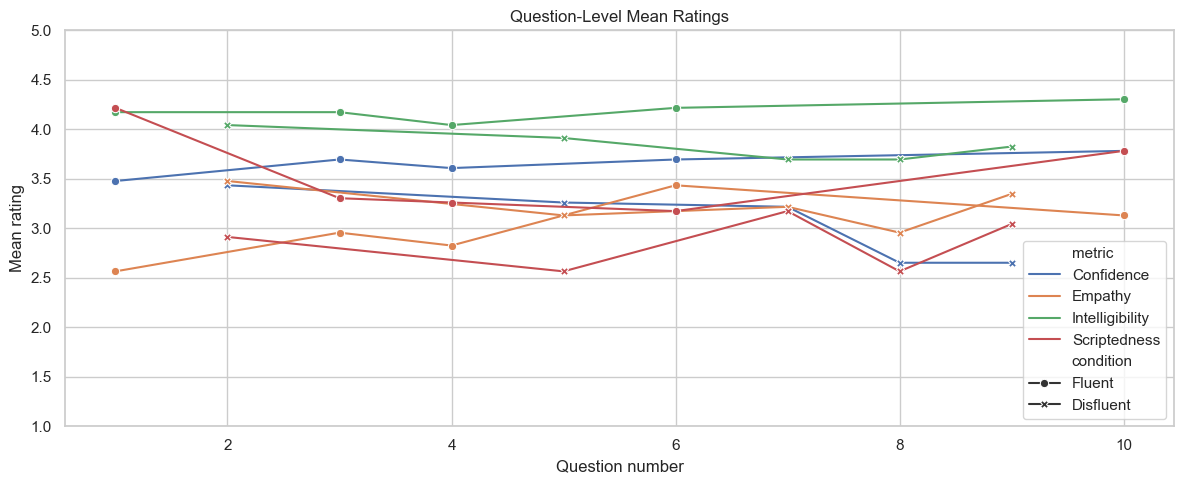

In [16]:
plt.figure(figsize=(12, 5))
plot_q = long_df.groupby(["question_num", "condition", "metric"], as_index=False)["score"].mean()
sns.lineplot(data=plot_q, x="question_num", y="score", hue="metric", style="condition", markers=True, dashes=False)
plt.title("Question-Level Mean Ratings")
plt.xlabel("Question number")
plt.ylabel("Mean rating")
plt.ylim(1, 5)
plt.tight_layout()
plt.show()
